'''
=================================================
Nama  : Muhammad Rifqi Sahib
=================================================

pertama melakukan instalasi pandas selenium dan beautifull soup dan webdriver
disini saya menambahkan matplotlib dikarenakan diakhir saya menambahkan visualisasi data

In [1]:
!pip install -q bs4 selenium pandas
!pip install -q webdriver-manager
!pip install -q matplotlib

Selanjutnya melakukan import tools tools yang kita gunakan dari library
yang sudah kita instal

In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt

from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from webdriver_manager.chrome import ChromeDriverManager
from selenium.webdriver.chrome.service import Service

from bs4 import BeautifulSoup

Menginstall bot untuk menduplikat web yang akan discrapping dengan menentukan
target data yaitu 90 dimulai dari page 1

In [3]:
options = Options()

driver = webdriver.Chrome(
    service=Service(ChromeDriverManager().install()),
    options=options
)

TARGET = 90
page = 1
data = []

Melakukan scrapping data dimulai memasukkan url lalu
menentukan waktu delay ataupun sleep 10 detik(ditentukan sendiri sesuai masing masing device) disini
saya menggunakan 10 detik walaupun lama hanya untuk bejaga jaga agar data terscrapping dengan sempurna perhalamannya.
selanjutnya kita melakukan scrapping dengan mengambil masing masing attribut yang kita gunakan dari web yang akan kita scrapping,
semua dilakukan dalam looping sampai mencapai target yaitu 90 data.

In [4]:
while len(data) < TARGET:

    url = f"https://studio.femaledaily.com/category/on-sale?page={page}&sort=price_asc&category=&min_price=&max_price=&sale=0&brand=&query="

    print(f"Scraping Page {page}")

    driver.get(url)

    time.sleep(10)

    soup = BeautifulSoup(driver.page_source, "html.parser")

    products = soup.find_all("div", class_="ProductCardFDS__Desktop")

    if len(products) == 0:
        print("Produk tidak ditemukan.")
        break

    for product in products:

        if len(data) >= TARGET:
            break

        brand = product.find("a", class_="product-brand")
        brand = brand.text.strip() if brand else None

        name = product.find("a", class_="product-title")
        name = name.text.strip() if name else None

        rating = product.find("span", class_="value")
        rating = rating.text.strip() if rating else None

        reviewer = product.find("span", class_="all-rating")
        reviewer = reviewer.text.strip() if reviewer else None

        discount_price = product.find("p", class_="reguler")
        discount_price = discount_price.text.strip() if discount_price else None

        price = product.find("p", class_="price")
        price = price.text.strip() if price else None

        data.append({
            "Brands": brand,
            "Product Name": name,
            "Discount Price": discount_price,
            "Price": price,
            "Rating": rating,
            "Reviewer": reviewer
        })

    page += 1

driver.quit()

Scraping Page 1
Scraping Page 2
Scraping Page 3
Scraping Page 4
Scraping Page 5
Scraping Page 6
Scraping Page 7
Scraping Page 8


lalu data kita simpan di variabel df lalu kita cek isi data teratasnya dan cek total data yang kita miliki

In [5]:
df = pd.DataFrame(data)

print(df.head())

print(f"\nTotal data : {len(df)}")

  Brands                   Product Name Discount Price       Price Rating  \
0  Goute   Glowsy Light Tinted Lip Balm      Rp 30.000   Rp 57.700    NaN   
1  Goute  Goublush All in 1 Cream Blush      Rp 40.000   Rp 43.200    4.3   
2  MINE.                Berry Bash 50ml     Rp 169.150  Rp 199.000    3.7   
3  MINE.          Ethereal Thermal 30ml     Rp 148.570  Rp 179.000    NaN   
4  MINE.            Rebel Instinct 30ml     Rp 148.570  Rp 179.000    NaN   

  Reviewer  
0      NaN  
1     (34)  
2      (9)  
3      NaN  
4      NaN  

Total data : 90


selanjutnya data kita ekspor menjadi female_daily_datakotor.csv

In [ ]:
df.to_csv("female_daily_datakotor.csv", index=False,na_rep="null")

kemudian data saya panggil kembali dengan nama variabel df_2

In [7]:
df_2 = pd.read_csv("C:/HACKTIV8/female_daily_datakotor.csv")

kemudian kita cek ulang isi dari file dengan melihat 10 data teratasnya dengan df.head(10)

In [8]:
df_2.head(10)

,Brands,Product Name,Discount Price,Price,Rating,Reviewer
0,Goute,Glowsy Light Tinted Lip Balm,Rp 30.000,Rp 57.700,NaN,NaN
1,Goute,Goublush All in 1 Cream Blush,Rp 40.000,Rp 43.200,4.3,(34)
2,MINE.,Berry Bash 50ml,Rp 169.150,Rp 199.000,3.7,(9)
3,MINE.,Ethereal Thermal 30ml,Rp 148.570,Rp 179.000,NaN,NaN
4,MINE.,Rebel Instinct 30ml,Rp 148.570,Rp 179.000,NaN,NaN
5,MINE.,Tatami 30ml,Rp 148.570,Rp 179.000,4.7,(27)
6,MINE.,Sakura Sake 30ml,Rp 148.570,Rp 179.000,NaN,NaN
7,MINE.,Tears of Jasmine,Rp 169.150,Rp 199.000,NaN,NaN
8,Verites,Extrait De Parfum - Amalfi Coast 50 ml,Rp 259.000,Rp 329.000,5.0,(1)
9,Verites,Eau De Parfum - Blooming Amoure 50 ml,Rp 220.000,Rp 269.000,NaN,NaN


karena data akan dicleaning disini kita mengecek type data dan total data yang kita miliki serta apakah ada nilai null ataupun data kosong dalam data yang kita miliki

In [9]:
df_2.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Brands          90 non-null     str    
 1   Product Name    90 non-null     str    
 2   Discount Price  90 non-null     str    
 3   Price           89 non-null     str    
 4   Rating          55 non-null     float64
 5   Reviewer        55 non-null     str    
dtypes: float64(1), str(5)
memory usage: 4.3 KB


kemudian disini kita menghapus karakter karakter yang tidak dipakai serta menggunakan\d agar angka menjadi angka bulat tanpa ada koma kemudian disini kita menggubah type data yang tadinya str menjadi numeric dan mengubahnya menjadi type data int

In [10]:
# Discount Price
df_2["Discount Price"] = (
    df_2["Discount Price"].str.replace(r"\D", "", regex=True).pipe(pd.to_numeric, errors="coerce").astype("Int64"))

# Price
df_2["Price"] = (
    df_2["Price"].str.replace(r"\D", "", regex=True).pipe(pd.to_numeric, errors="coerce").astype("Int64"))

# Reviewer
df_2["Reviewer"] = (
    df_2["Reviewer"].str.replace(r"\D", "", regex=True).pipe(pd.to_numeric, errors="coerce").astype("Int64"))

kemudian kita mengecek kembali type data yang sudah di ubah

In [11]:
df_2.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Brands          90 non-null     str    
 1   Product Name    90 non-null     str    
 2   Discount Price  90 non-null     Int64  
 3   Price           89 non-null     Int64  
 4   Rating          55 non-null     float64
 5   Reviewer        55 non-null     Int64  
dtypes: Int64(3), float64(1), str(2)
memory usage: 4.6 KB


menampilkan ulang 10 data teratas hanya untuk memvalidasi perubahan

In [12]:
df_2.head(10)

,Brands,Product Name,Discount Price,Price,Rating,Reviewer
0,Goute,Glowsy Light Tinted Lip Balm,30000,57700,NaN,<NA>
1,Goute,Goublush All in 1 Cream Blush,40000,43200,4.3,34
2,MINE.,Berry Bash 50ml,169150,199000,3.7,9
3,MINE.,Ethereal Thermal 30ml,148570,179000,NaN,<NA>
4,MINE.,Rebel Instinct 30ml,148570,179000,NaN,<NA>
5,MINE.,Tatami 30ml,148570,179000,4.7,27
6,MINE.,Sakura Sake 30ml,148570,179000,NaN,<NA>
7,MINE.,Tears of Jasmine,169150,199000,NaN,<NA>
8,Verites,Extrait De Parfum - Amalfi Coast 50 ml,259000,329000,5.0,1
9,Verites,Eau De Parfum - Blooming Amoure 50 ml,220000,269000,NaN,<NA>


kemudian melakukan ekspor data yang sudah bersih menjadi "female_daily_clean.csv"

In [17]:
df_2.to_csv("female_daily_clean.csv", index=False,na_rep="null")

dibawah merupakan tambahan yang saya tambahkan dimulai dari
VISUALISASI DATA KE-1 disini saya ingin menampilkan top 10 product dengan reviewer terbanyak serta rating masing masing produknya
sehingga disini kita menggunakan 3 variabel sebagai variabel x atauapun horizontal yaitu product name, sebagai variable Y atau sebagai variabel vertikalnya yaitu reviewer ataupun jumlah orang yang meriview disini rating sebagai text pengikut atau penanda dari setiap titik

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11484\2103157189.py:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


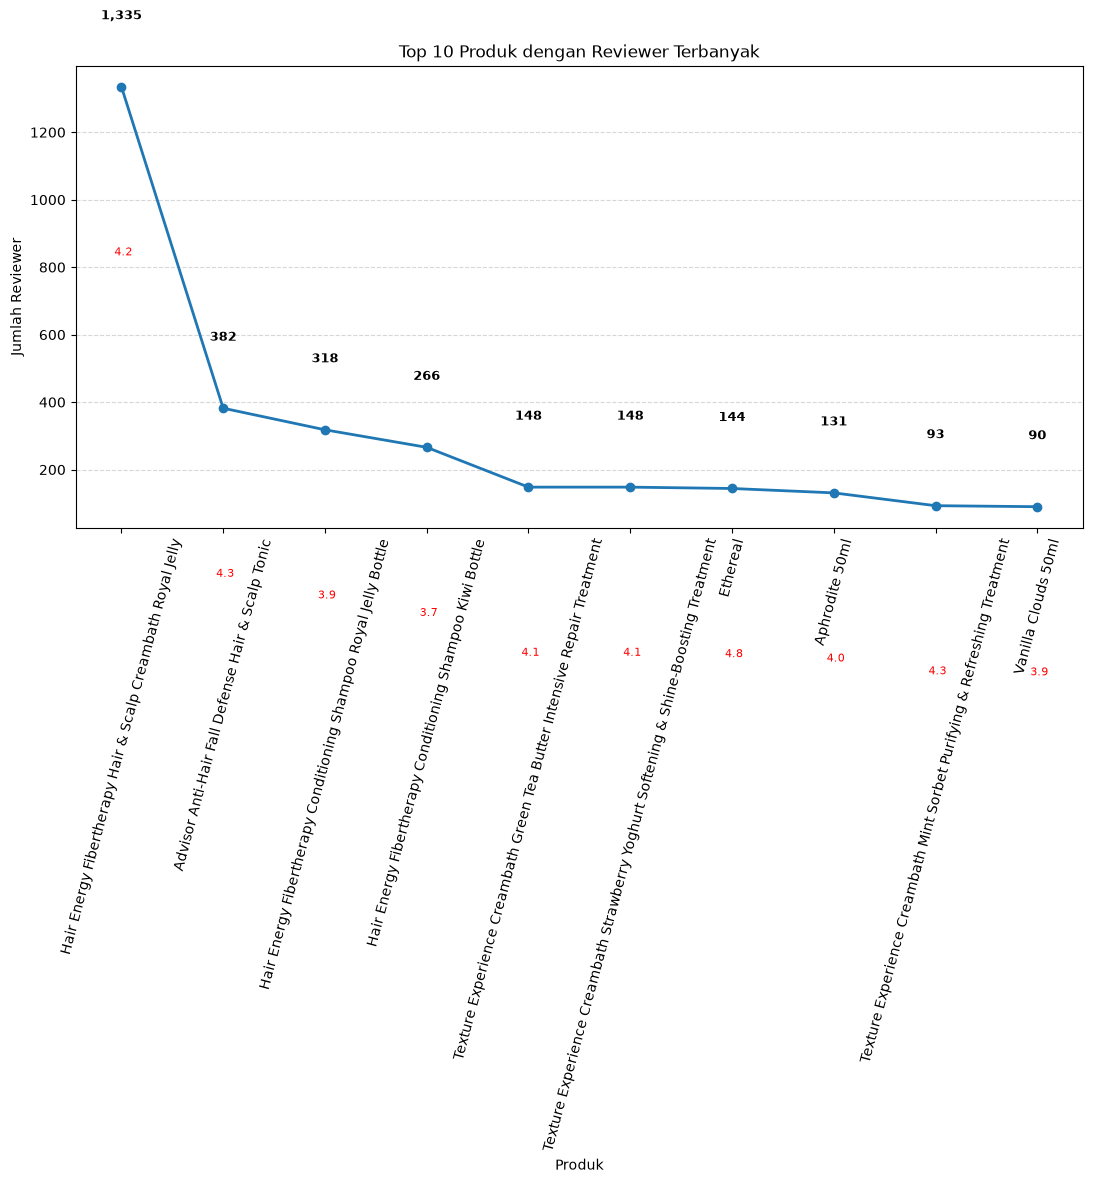

In [14]:
top_reviewer = (df_2.dropna(subset=["Reviewer"]).sort_values("Reviewer", ascending=False).head(10))

plt.figure(figsize=(13,6))

plt.plot(top_reviewer["Product Name"],top_reviewer["Reviewer"],marker="o",linewidth=2)

for x, y in zip(top_reviewer["Product Name"], top_reviewer["Reviewer"]):
    plt.text(x,y + 200,
    f"{int(y):,}",
    ha="center",fontsize=9,fontweight="bold"
    )

for x, y, rating in zip(
        top_reviewer["Product Name"],
        top_reviewer["Reviewer"],
        top_reviewer["Rating"]):
    plt.text(x, y - 500,
        f" {rating:.1f}",
        ha="center",fontsize=8,color="red"
    )

plt.title("Top 10 Produk dengan Reviewer Terbanyak")
plt.xlabel("Produk")
plt.ylabel("Jumlah Reviewer")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

VISUALISASI KE-2 disini saya ingin tau brands apa saja yang memiliki reviewer banyak serta rating rata ratanya berapa sehingga disini menggunakan 3 variabel yaitu brands sebagai xlabel, reviewer sebagai lebih tepatnya keseluruhan (sum) reviewer berdasarkan brands sebagai nilai Y dan rata rata rating sebagai text penjelas masing masing brands.

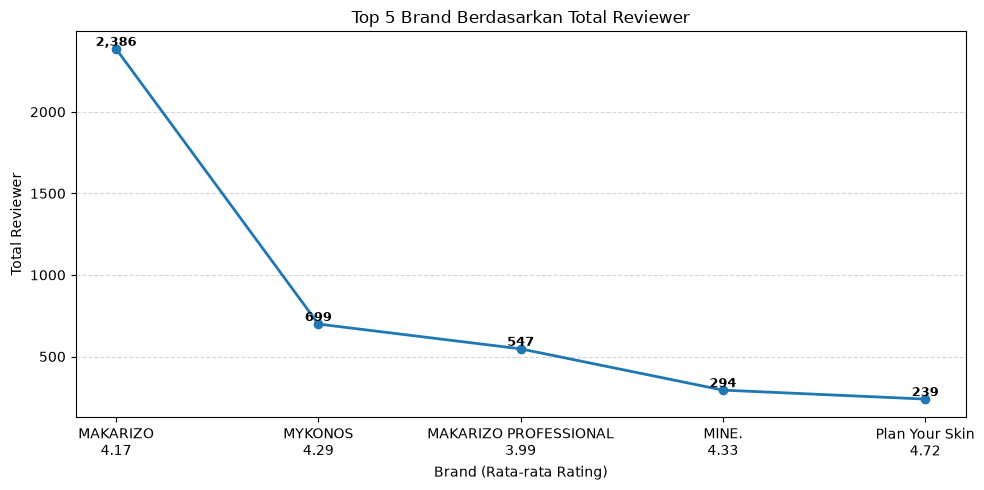

In [15]:
brand_summary = (
    df_2.groupby("Brands").agg(
            Total_Reviewer=("Reviewer", "sum"),
            Average_Rating=("Rating", "mean")
        ).sort_values("Total_Reviewer", ascending=False).head(5))

labels = [
    f"{brand}\n{rating:.2f}"
    for brand, rating in zip(
        brand_summary.index,
        brand_summary["Average_Rating"]
    )
]

plt.figure(figsize=(10,5))

plt.plot(labels,brand_summary["Total_Reviewer"],
    marker="o",linewidth=2)

for x, y in zip(labels, brand_summary["Total_Reviewer"]):
    plt.text(x,y,
        f"{int(y):,}",
        ha="center",va="bottom",fontsize=9,fontweight="bold")

plt.title("Top 5 Brand Berdasarkan Total Reviewer")
plt.xlabel("Brand (Rata-rata Rating)")
plt.ylabel("Total Reviewer")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

VISUALISASI DATA KE-3 disini saya ingin tau top 5 brands yang memiliki produk termurah berdasarkan rating dan jumlah reviewernya
dimulai dari mengambil 4 variabel yaitu brands, discount price, rating, reviewer kemudian yang menjadi label y ialah harga atau pun bisa dikatakan mata uang kemudian harga diskon/ discount price diletakkan sebagai plot atau titik dan sisa variabel lain sebagai deskripsi dari masing masing plot atau titik

NOTE : jikalau ingin menampilkan top top berapa masing masing visualisasi data tinggal ubah bagian head lalu ingin mengedit penulisan dari text tinggal ubah pada bagian PLT.TEXT

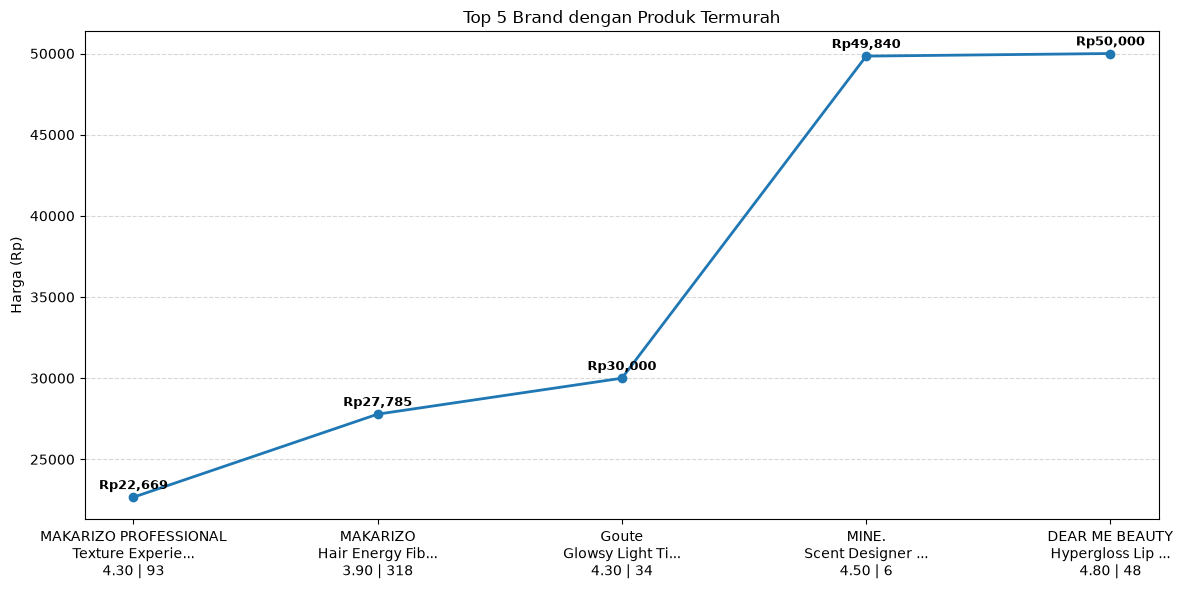

In [16]:
produk = (
    df_2.sort_values(
        by=["Brands", "Discount Price", "Rating", "Reviewer"],
        ascending=[True, True, False, False]
    ).groupby("Brands").first().reset_index())

top5 = (
    produk.sort_values(
        by=["Discount Price", "Rating", "Reviewer"],
        ascending=[True, False, False]
    ).head(5))

labels = [
    f"{brand}\n{produk[:15]}...\n{rating:.2f} | {int(reviewer):,}"
    for brand, produk, rating, reviewer in zip(
        top5["Brands"],
        top5["Product Name"],
        top5["Rating"],
        top5["Reviewer"]
    )
]

plt.figure(figsize=(12,6))

plt.plot(
    labels,
    top5["Discount Price"],
    marker="o",
    linewidth=2
)

for x, y in zip(labels, top5["Discount Price"]):
    plt.text(
        x,y + 500,
        f"Rp{y:,}",
        ha="center",fontsize=9,fontweight="bold")

plt.title("Top 5 Brand dengan Produk Termurah")
plt.ylabel("Harga (Rp)")
plt.xticks(rotation=0)

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()